# Steering Shifts Predictions in Physically Expected Directions

We intervene on the CLS residual stream along four physical concept directions and measure how the model's predicted-class distribution changes. For each concept, we sweep the steering coefficient $\alpha$ on a physically motivated source class and save a decision-migration plot.

In [1]:
# ruff: noqa: E402
import json
import warnings

from tqdm import TqdmWarning
warnings.filterwarnings("ignore", category=TqdmWarning)

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

from jetdirections.config import (
    CHECKPOINT_DIR, DROPOUT, MODEL_DIM, NUM_CLASSES, NUM_HEADS,
    NUM_LAYERS, PROJ_ROOT, VAL_DATA_DIR,
)
from jetdirections.data.dataset import JetClassDataset
from jetdirections.data.sampling import load_class_batch
from jetdirections.interp import (
    apply_steering,
)
from jetdirections.model.transformer import JetTagTransformer
from jetdirections.training.metrics import CLASS_NAMES

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LAYERS = [1, 2, 3, 4]
ALPHAS = [-8, -6, -4, -3, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 3, 4, 6, 8]
N_SOURCE = 50_000
RESULTS_DIR = PROJ_ROOT / "experiments" / "results" / "physical_concept_steering"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DIRECTIONS_DIR = PROJ_ROOT / "experiments" / "results" / "physical_concept_steering" / "directions"
print(f"device: {DEVICE}")

device: cuda


## Load Model

In [2]:
checkpoint = torch.load(CHECKPOINT_DIR / "jetclass_transformer.pt", map_location=DEVICE, weights_only=False)
model = JetTagTransformer(
    input_dim=17, embed_dim=MODEL_DIM, num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS, num_classes=NUM_CLASSES, dropout=DROPOUT,
).to(DEVICE)
state = checkpoint["model_state_dict"] if "model_state_dict" in checkpoint else checkpoint
model.load_state_dict(state)
model.eval();

## Load Steering Vector Directions and Data Batches


In [3]:
dataset = JetClassDataset(VAL_DATA_DIR, shuffle_files=False)
directions = {
    name: torch.load(DIRECTIONS_DIR / f"{name}_direction.pt", weights_only=True)
    for name in ("mass", "multiplicity", "charge", "displacement")
}
orders = json.loads((DIRECTIONS_DIR / "class_orders.json").read_text())
source_batches = {
    "mass": load_class_batch(dataset, "Wqq", N_SOURCE, seed=0),
    "multiplicity": load_class_batch(dataset, "Hcc", N_SOURCE, seed=0),
    "charge": load_class_batch(dataset, "Zqq", N_SOURCE, seed=0),
    "displacement": load_class_batch(dataset, "Hgg", N_SOURCE, seed=0),
}


## Define the steering sweep

Apply a direction to the CLS token at blocks 1--4 and return the predicted-class fractions for each value of $\alpha$.

In [4]:
def predicted_fractions(batch, vectors, class_order):
    order = [CLASS_NAMES.index(name) for name in class_order]
    steering = {layer: (vector, torch.zeros_like(vector)) for layer, vector in vectors.items()}
    fractions = []
    for alpha in ALPHAS:
        logits = apply_steering(model, batch, steering, scale=float(alpha))
        predictions = logits.argmax(dim=1)
        counts = torch.bincount(predictions, minlength=len(CLASS_NAMES)).float() / len(predictions)
        fractions.append(counts[order].numpy())
    return np.stack(fractions)

def plot_migration(name, fractions, order, xlabel):
    fig, ax = plt.subplots(figsize=(7.6, 4.4))
    colors = plt.cm.turbo(np.linspace(0.05, 0.95, len(order)))
    ax.stackplot(ALPHAS, *(100 * fractions[:, i] for i in range(len(order))), labels=order, colors=colors)
    ax.axvline(0, color="k", lw=0.8, ls="--")
    ax.set(xlim=(min(ALPHAS), max(ALPHAS)), ylim=(0, 100), xlabel=xlabel, ylabel="predicted-class fraction (%)")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="class", frameon=False, fontsize=9)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"{name}_decision_migration.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## Jet-mass steering

Steer $W\to qq$ jets along the mass direction; negative $\alpha$ should favor lighter classes and positive $\alpha$ heavier classes.

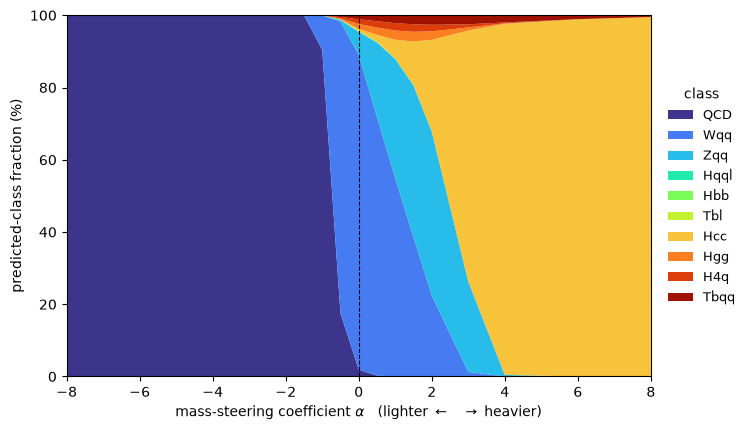

In [5]:
mass_fractions = predicted_fractions(source_batches["mass"], directions["mass"], orders["mass"])
plot_migration("mass", mass_fractions, orders["mass"], r"mass-steering coefficient $\alpha$   (lighter $\leftarrow$   $\rightarrow$ heavier)")

## Particle-multiplicity steering

Steer $H\to c\bar{c}$ jets along the multiplicity direction; positive $\alpha$ should favor classes with larger particle multiplicity.

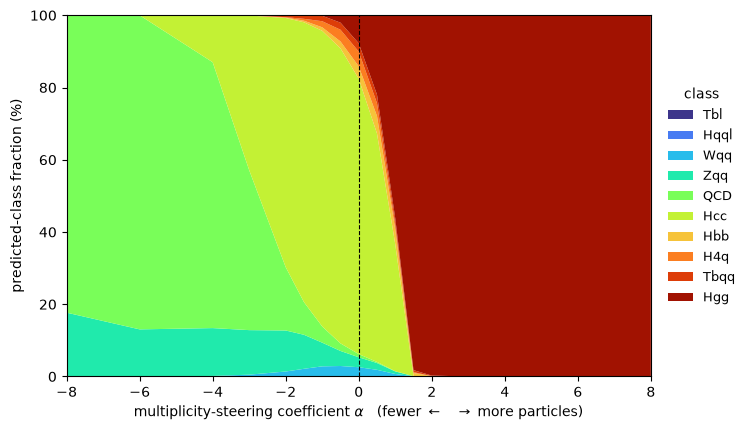

In [6]:
multiplicity_fractions = predicted_fractions(source_batches["multiplicity"], directions["multiplicity"], orders["multiplicity"])
plot_migration("multiplicity", multiplicity_fractions, orders["multiplicity"], r"multiplicity-steering coefficient $\alpha$   (fewer $\leftarrow$   $\rightarrow$ more particles)")

## Jet-charge steering

Steer $Z\to q\bar{q}$ jets along the charge direction; positive $\alpha$ should favor classes with more positive mean jet charge, including $W\to qq$.

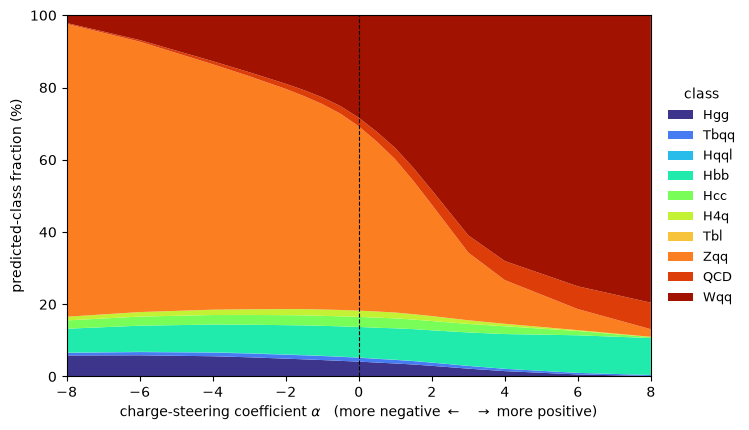

In [7]:
charge_fractions = predicted_fractions(source_batches["charge"], directions["charge"], orders["charge"])
plot_migration("charge", charge_fractions, orders["charge"], r"charge-steering coefficient $\alpha$   (more negative $\leftarrow$   $\rightarrow$ more positive)")

## Track-displacement steering

Steer $H\to gg$ jets along the paper-definition displacement direction; positive $\alpha$ should favor displaced heavy-flavor classes such as $H\to b\bar{b}$ and $H\to c\bar{c}$.

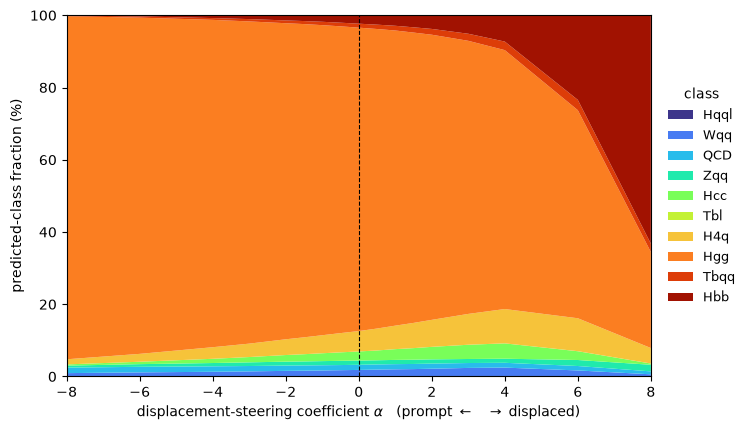

In [8]:
displacement_fractions = predicted_fractions(source_batches["displacement"], directions["displacement"], orders["displacement"])
plot_migration("displacement", displacement_fractions, orders["displacement"], r"displacement-steering coefficient $\alpha$   (prompt $\leftarrow$   $\rightarrow$ displaced)")

## Plot and Save Predicted-Class Fractions Data

In [9]:
results = {
    name: {"alphas": ALPHAS, "class_order": orders[name], "fractions": fractions.tolist()}
    for name, fractions in {
        "mass": mass_fractions, "multiplicity": multiplicity_fractions,
        "charge": charge_fractions, "displacement": displacement_fractions,
    }.items()
}
(RESULTS_DIR / "migration_fractions.json").write_text(json.dumps(results, indent=2))

for name, result in results.items():
    header = "| $\\alpha$ | " + " | ".join(result["class_order"]) + " |"
    separator = "|---:|" + "---:|" * len(result["class_order"])
    rows = [header, separator]
    for alpha, fractions in zip(result["alphas"], result["fractions"]):
        values = " | ".join(f"{100 * fraction:.1f}" for fraction in fractions)
        rows.append(f"| {alpha:g} | {values} |")
    display(Markdown(f"### {name.capitalize()} steering: predicted-class fractions (\\%)\n\n" + "\n".join(rows)))
    (RESULTS_DIR / f"{name}_predicted_class_fractions.md").write_text("\n".join(rows) + "\n")


### Mass steering: predicted-class fractions (\%)

| $\alpha$ | QCD | Wqq | Zqq | Hqql | Hbb | Tbl | Hcc | Hgg | H4q | Tbqq |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| -8 | 100.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| -6 | 100.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| -4 | 100.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| -3 | 100.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| -2 | 100.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| -1.5 | 100.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| -1 | 90.5 | 9.5 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| -0.5 | 17.5 | 80.7 | 0.5 | 0.0 | 0.0 | 0.0 | 0.1 | 0.2 | 0.4 | 0.5 |
| 0 | 1.9 | 87.1 | 6.4 | 0.1 | 0.2 | 0.0 | 0.6 | 1.4 | 1.3 | 1.1 |
| 0.5 | 0.2 | 71.6 | 20.6 | 0.1 | 0.2 | 0.0 | 1.9 | 2.0 | 1.8 | 1.6 |
| 1 | 0.0 | 54.9 | 33.0 | 0.1 | 0.1 | 0.0 | 5.2 | 2.5 | 2.1 | 2.2 |
| 1.5 | 0.0 | 38.5 | 42.0 | 0.0 | 0.1 | 0.0 | 12.0 | 2.7 | 2.1 | 2.5 |
| 2 | 0.0 | 22.4 | 45.4 | 0.0 | 0.0 | 0.0 | 25.3 | 2.3 | 1.8 | 2.6 |
| 3 | 0.0 | 1.3 | 25.1 | 0.0 | 0.0 | 0.0 | 69.5 | 0.8 | 0.9 | 2.5 |
| 4 | 0.0 | 0.0 | 0.4 | 0.0 | 0.0 | 0.0 | 97.1 | 0.2 | 0.3 | 2.0 |
| 6 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 98.9 | 0.0 | 0.0 | 1.1 |
| 8 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 99.5 | 0.0 | 0.0 | 0.5 |

### Multiplicity steering: predicted-class fractions (\%)

| $\alpha$ | Tbl | Hqql | Wqq | Zqq | QCD | Hcc | Hbb | H4q | Tbqq | Hgg |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| -8 | 0.0 | 0.0 | 0.0 | 17.7 | 82.3 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| -6 | 0.0 | 0.0 | 0.0 | 13.0 | 87.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| -4 | 0.0 | 0.0 | 0.2 | 13.2 | 73.6 | 13.0 | 0.0 | 0.0 | 0.0 | 0.0 |
| -3 | 0.0 | 0.0 | 0.5 | 12.3 | 44.3 | 42.8 | 0.0 | 0.0 | 0.1 | 0.0 |
| -2 | 0.0 | 0.1 | 1.3 | 11.4 | 17.5 | 69.0 | 0.1 | 0.1 | 0.5 | 0.0 |
| -1.5 | 0.0 | 0.1 | 2.0 | 9.4 | 9.0 | 77.5 | 0.4 | 0.5 | 1.0 | 0.0 |
| -1 | 0.0 | 0.1 | 2.7 | 6.6 | 4.5 | 81.8 | 1.0 | 1.7 | 1.5 | 0.1 |
| -0.5 | 0.0 | 0.1 | 2.8 | 4.2 | 2.1 | 81.7 | 1.9 | 3.2 | 2.0 | 2.0 |
| 0 | 0.0 | 0.1 | 2.4 | 2.8 | 0.9 | 76.2 | 3.4 | 4.1 | 2.3 | 7.8 |
| 0.5 | 0.1 | 0.1 | 1.7 | 1.9 | 0.3 | 63.2 | 4.8 | 3.6 | 2.4 | 22.0 |
| 1 | 0.1 | 0.0 | 0.6 | 0.7 | 0.0 | 35.2 | 4.1 | 1.4 | 1.6 | 56.2 |
| 1.5 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.8 | 0.2 | 0.6 | 98.2 |
| 2 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.1 | 0.0 | 0.1 | 99.7 |
| 3 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 100.0 |
| 4 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 100.0 |
| 6 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 100.0 |
| 8 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 100.0 |

### Charge steering: predicted-class fractions (\%)

| $\alpha$ | Hgg | Tbqq | Hqql | Hbb | Hcc | H4q | Tbl | Zqq | QCD | Wqq |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| -8 | 5.8 | 0.7 | 0.1 | 6.6 | 2.3 | 1.0 | 0.0 | 81.1 | 0.2 | 2.1 |
| -6 | 5.9 | 0.9 | 0.1 | 7.2 | 2.5 | 1.2 | 0.0 | 74.9 | 0.5 | 6.8 |
| -4 | 5.6 | 1.0 | 0.1 | 7.7 | 2.6 | 1.5 | 0.0 | 67.9 | 0.8 | 12.7 |
| -3 | 5.3 | 1.0 | 0.1 | 7.9 | 2.7 | 1.6 | 0.0 | 64.5 | 1.1 | 15.8 |
| -2 | 4.9 | 1.1 | 0.1 | 8.1 | 2.8 | 1.7 | 0.0 | 61.0 | 1.4 | 19.0 |
| -1.5 | 4.7 | 1.1 | 0.1 | 8.2 | 2.8 | 1.7 | 0.0 | 59.0 | 1.6 | 20.7 |
| -1 | 4.6 | 1.1 | 0.1 | 8.3 | 2.8 | 1.7 | 0.0 | 56.9 | 1.9 | 22.7 |
| -0.5 | 4.3 | 1.1 | 0.1 | 8.4 | 2.8 | 1.7 | 0.0 | 54.3 | 2.1 | 25.2 |
| 0 | 4.1 | 1.1 | 0.1 | 8.5 | 2.8 | 1.7 | 0.0 | 51.0 | 2.4 | 28.3 |
| 0.5 | 3.9 | 1.0 | 0.1 | 8.6 | 2.8 | 1.7 | 0.0 | 47.0 | 2.7 | 32.3 |
| 1 | 3.6 | 1.0 | 0.1 | 8.7 | 2.8 | 1.6 | 0.0 | 42.4 | 3.1 | 36.8 |
| 1.5 | 3.3 | 0.9 | 0.0 | 8.8 | 2.6 | 1.5 | 0.0 | 36.9 | 3.6 | 42.3 |
| 2 | 3.0 | 0.9 | 0.0 | 8.9 | 2.6 | 1.4 | 0.0 | 30.8 | 4.0 | 48.4 |
| 3 | 2.2 | 0.8 | 0.0 | 9.2 | 2.4 | 1.0 | 0.0 | 18.7 | 4.8 | 60.9 |
| 4 | 1.5 | 0.6 | 0.0 | 9.6 | 2.2 | 0.7 | 0.0 | 12.1 | 5.3 | 68.0 |
| 6 | 0.6 | 0.4 | 0.0 | 10.4 | 1.2 | 0.2 | 0.0 | 5.8 | 6.3 | 75.0 |
| 8 | 0.1 | 0.3 | 0.0 | 10.2 | 0.3 | 0.1 | 0.0 | 2.1 | 7.3 | 79.6 |

### Displacement steering: predicted-class fractions (\%)

| $\alpha$ | Hqql | Wqq | QCD | Zqq | Hcc | Tbl | H4q | Hgg | Tbqq | Hbb |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| -8 | 0.0 | 0.9 | 1.5 | 0.5 | 0.3 | 0.0 | 1.4 | 95.0 | 0.2 | 0.0 |
| -6 | 0.0 | 1.1 | 1.5 | 0.7 | 0.7 | 0.0 | 2.2 | 93.1 | 0.3 | 0.3 |
| -4 | 0.0 | 1.3 | 1.5 | 0.9 | 1.2 | 0.0 | 3.2 | 90.6 | 0.5 | 0.8 |
| -3 | 0.0 | 1.4 | 1.5 | 1.0 | 1.5 | 0.0 | 3.7 | 89.2 | 0.6 | 1.1 |
| -2 | 0.0 | 1.6 | 1.5 | 1.1 | 1.8 | 0.0 | 4.4 | 87.5 | 0.8 | 1.4 |
| -1.5 | 0.0 | 1.6 | 1.5 | 1.1 | 2.0 | 0.0 | 4.7 | 86.7 | 0.8 | 1.6 |
| -1 | 0.0 | 1.7 | 1.4 | 1.1 | 2.2 | 0.0 | 5.0 | 85.8 | 0.9 | 1.8 |
| -0.5 | 0.0 | 1.7 | 1.4 | 1.2 | 2.3 | 0.0 | 5.3 | 84.9 | 1.0 | 2.1 |
| 0 | 0.0 | 1.8 | 1.4 | 1.2 | 2.5 | 0.0 | 5.6 | 84.0 | 1.1 | 2.3 |
| 0.5 | 0.0 | 1.9 | 1.4 | 1.2 | 2.7 | 0.0 | 6.1 | 82.9 | 1.2 | 2.6 |
| 1 | 0.0 | 2.0 | 1.4 | 1.2 | 3.0 | 0.0 | 6.5 | 81.7 | 1.3 | 2.9 |
| 1.5 | 0.0 | 2.0 | 1.4 | 1.2 | 3.2 | 0.0 | 7.0 | 80.4 | 1.5 | 3.3 |
| 2 | 0.0 | 2.2 | 1.4 | 1.2 | 3.5 | 0.0 | 7.5 | 78.9 | 1.6 | 3.8 |
| 3 | 0.0 | 2.4 | 1.4 | 1.1 | 3.9 | 0.0 | 8.5 | 75.6 | 2.0 | 5.1 |
| 4 | 0.0 | 2.5 | 1.3 | 1.1 | 4.2 | 0.0 | 9.5 | 71.7 | 2.4 | 7.3 |
| 6 | 0.0 | 1.7 | 1.2 | 1.7 | 2.4 | 0.0 | 9.1 | 57.6 | 2.9 | 23.4 |
| 8 | 0.0 | 0.6 | 0.8 | 1.8 | 0.3 | 0.0 | 4.3 | 26.6 | 2.3 | 63.2 |